<a href="https://colab.research.google.com/github/jasonpratt8154-del/MTECH-Python-Final-Project/blob/main/Hybrid_03_Import_to_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jason's Hybrid 03 - Import to Python

The data intentionally has missing values and variables to simulate data in real life and to help provide the ability to clean the data as part of the final project

In [1]:
!pip install ucimlrepo



from ucimlrepo import fetch_ucirepo

# fetch dataset
census_income = fetch_ucirepo(id=20)

# data (as pandas dataframes)
X = census_income.data.features
y = census_income.data.targets

# metadata
print(census_income.metadata)

# variable information
print(census_income.variables)

{'uci_id': 20, 'name': 'Census Income', 'repository_url': 'https://archive.ics.uci.edu/dataset/20/census+income', 'data_url': 'https://archive.ics.uci.edu/static/public/20/data.csv', 'abstract': 'Predict whether income exceeds $50K/yr based on census data.  Also known as Adult dataset.', 'area': 'Social Science', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 48842, 'num_features': 14, 'feature_types': ['Categorical', 'Integer'], 'demographics': ['Age', 'Income', 'Education Level', 'Other', 'Race', 'Sex'], 'target_col': ['income'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1996, 'last_updated': 'Mon Sep 09 2024', 'dataset_doi': '10.24432/C5GP7S', 'creators': ['Ron Kohavi'], 'intro_paper': None, 'additional_info': {'summary': 'Extraction was done by Barry Becker from the 1994 Census database.  A set of reasonably clean records was extracted using the following conditions: ((AAGE>16) && 

In [2]:
import pandas as pd

df = census_income.data.features
df['income'] = census_income.data.targets
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


# Data Cleaning

In [3]:
# To figure out which columns have missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       47879 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      47876 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48568 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB


In [5]:
# This cleans the column - I did use google to figure out this
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].astype(str).str.strip().str.rstrip('.')

# To replace values that are incomplete/null
df.replace('?', None, inplace=True)
df.replace('nan', None, inplace=True)

# To fill values in categorical columns
missing_cols = ['workclass', 'occupation', 'native-country']
for col in missing_cols:
    df[col] = df[col].fillna('Unknown')

# To fix duplicate values
print(f"Number of duplicate rows before removal: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)
print(f"Shape of dataset after cleaning: {df.shape}")

# New clean data
display(df.info())
display(df.head())

Number of duplicate rows before removal: 0
Shape of dataset after cleaning: (48790, 15)
<class 'pandas.core.frame.DataFrame'>
Index: 48790 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48790 non-null  int64 
 1   workclass       48790 non-null  object
 2   fnlwgt          48790 non-null  int64 
 3   education       48790 non-null  object
 4   education-num   48790 non-null  int64 
 5   marital-status  48790 non-null  object
 6   occupation      48790 non-null  object
 7   relationship    48790 non-null  object
 8   race            48790 non-null  object
 9   sex             48790 non-null  object
 10  capital-gain    48790 non-null  int64 
 11  capital-loss    48790 non-null  int64 
 12  hours-per-week  48790 non-null  int64 
 13  native-country  48790 non-null  object
 14  income          48790 non-null  object
dtypes: int64(6), object(9)
memory usage: 6.0+ MB


None

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


# Data Manipulation

In [14]:
# To group and aggregate the data by education and income
education_income = df.groupby(['education', 'income']).agg(
    average_age=('age', 'mean'),
    average_hours_worked=('hours-per-week', 'mean'),
    total_count=('age', 'count')
).reset_index()

print(education_income.head())

# To filter for full-time individuals making 50k+
income_fulltime = df[(df['income'] == '>50K') & (df['hours-per-week'] >= 40)]

# To sort by capital gain
capital_gain = income_fulltime.sort_values(by='capital-gain', ascending=False)

print(capital_gain[['age', 'education', 'occupation', 'hours-per-week', 'capital-gain']].head())

  education income  average_age  average_hours_worked  total_count
0      10th  <=50K    37.102919             36.407834         1302
1      10th   >50K    49.873563             45.643678           87
2      11th  <=50K    31.383721             33.338372         1720
3      11th   >50K    46.315217             45.434783           92
4      12th  <=50K    31.350906             34.616145          607
       age    education      occupation  hours-per-week  capital-gain
4656    37   Assoc-acdm  Prof-specialty              40         99999
4898    37  Prof-school  Prof-specialty              50         99999
5098    39  Prof-school  Prof-specialty              65         99999
5473    44  Prof-school  Prof-specialty              65         99999
47011   40    Doctorate  Prof-specialty              55         99999


# Visualizations

/tmp/ipykernel_6590/2141862095.py:19: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




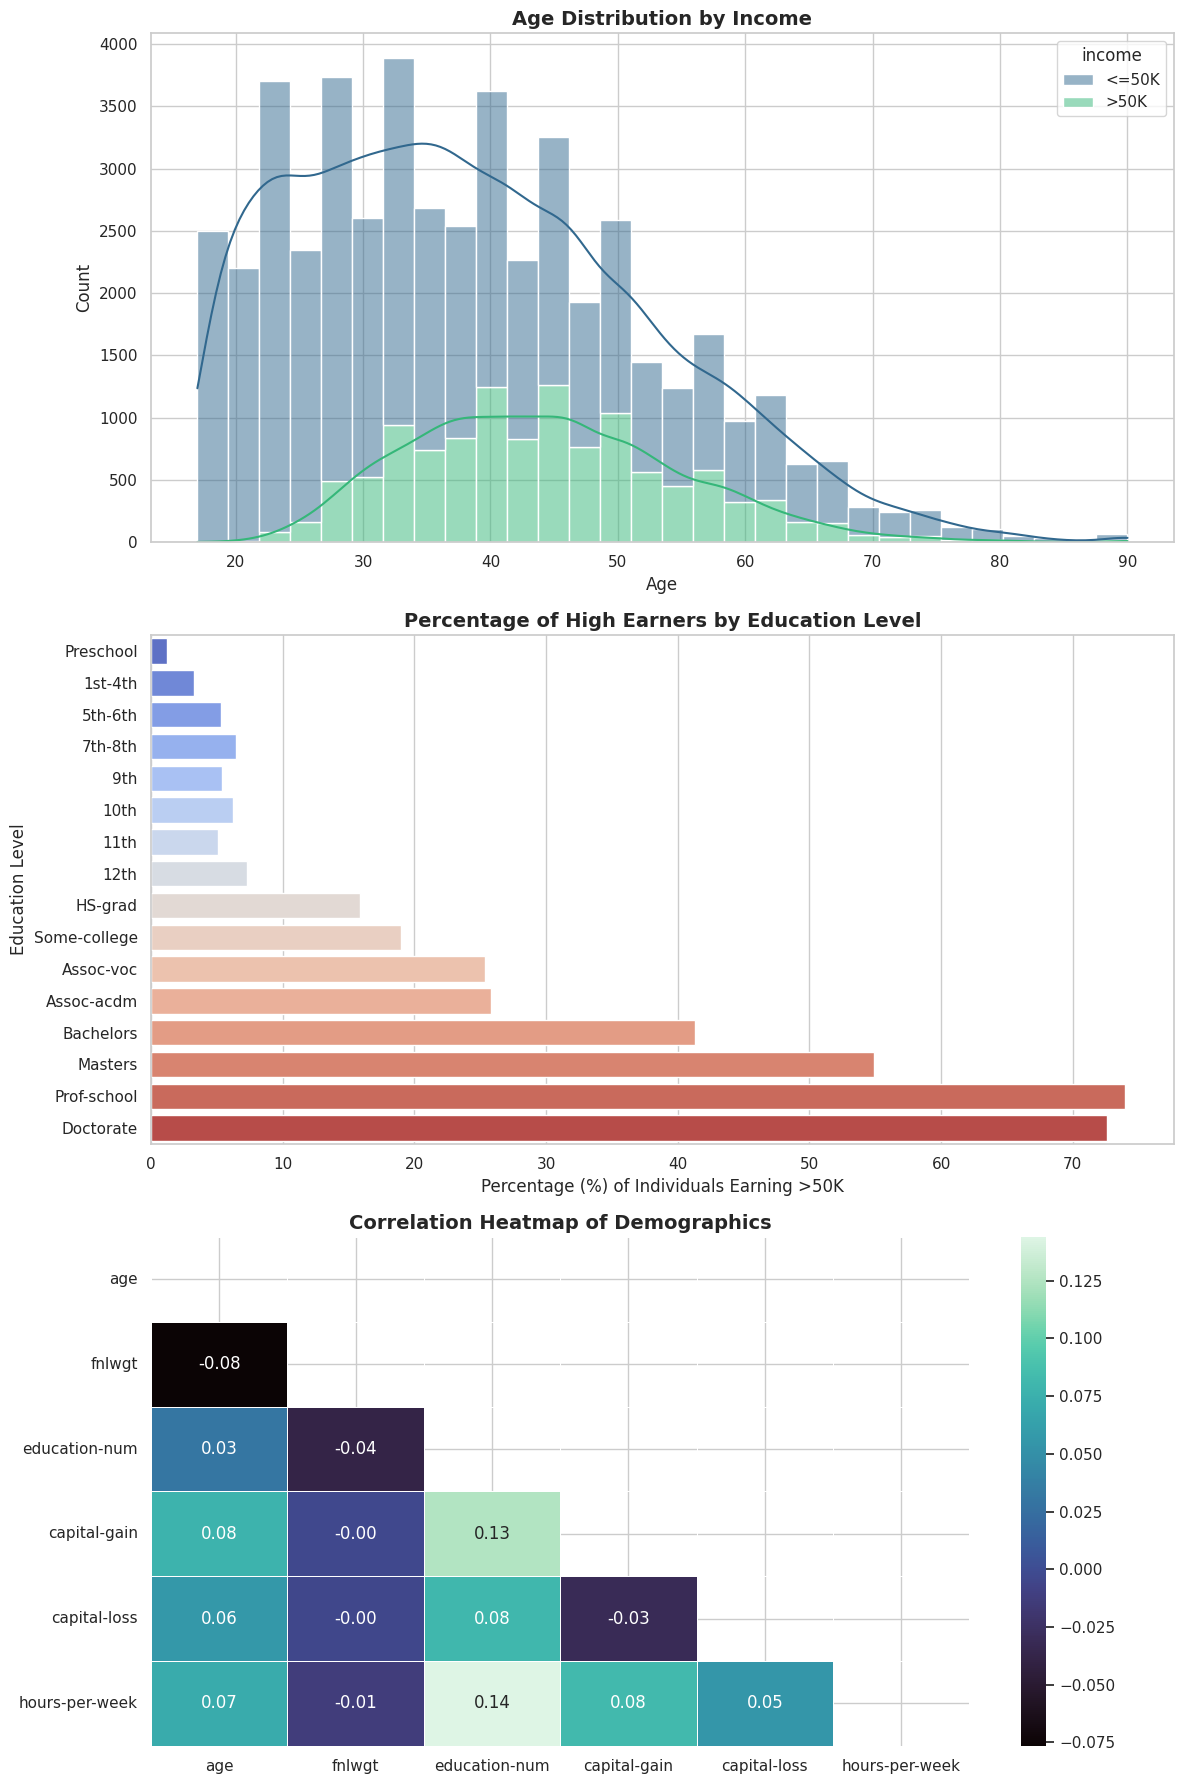

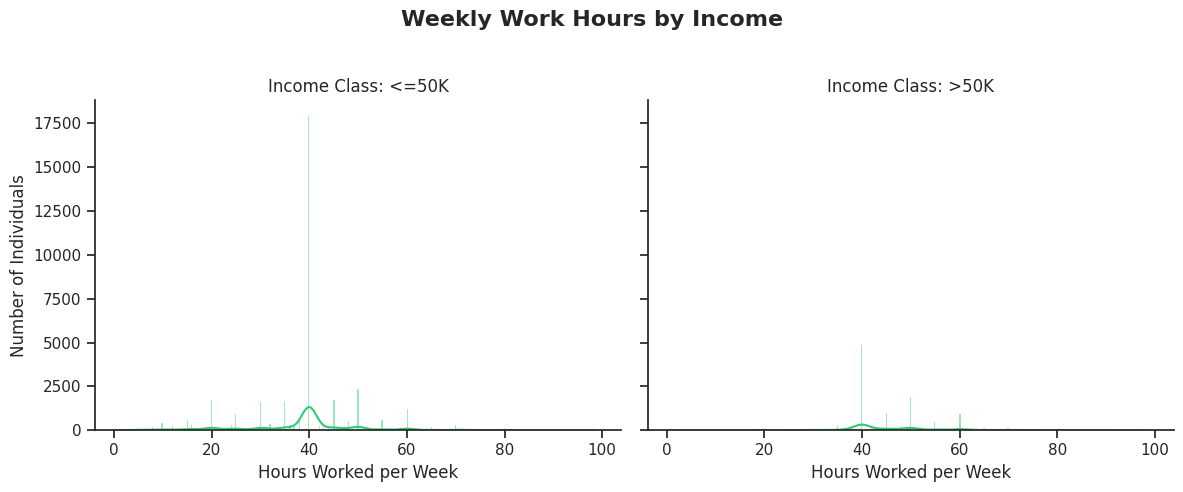

In [22]:
# These visualizations are modified versions from the sources we were given, with some google help to make them look more professional
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.express as px


sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(12, 18))

sns.histplot(data=df, x='age', hue='income', multiple='stack', kde=True, palette='viridis', ax=axes[0],bins=30)
axes[0].set_title('Age Distribution by Income', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Age', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)

education_order = df.groupby('education')['education-num'].mean().sort_values().index
df_high_earn = df.groupby('education')['income'].value_counts(normalize=True).unstack().reset_index()
df_high_earn['High Earner %'] = df_high_earn['>50K'] * 100

sns.barplot(data=df_high_earn, x='High Earner %', y='education', order=education_order,palette='coolwarm', ax=axes[1])
axes[1].set_title('Percentage of High Earners by Education Level', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Percentage (%) of Individuals Earning >50K', fontsize=12)
axes[1].set_ylabel('Education Level', fontsize=12)

corr_matrix = df.select_dtypes(include=['int64', 'float64']).corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, annot=True, mask=mask, cmap='mako', fmt='.2f', linewidths=0.5, ax=axes[2])
axes[2].set_title('Correlation Heatmap of Demographics', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

sns.set_theme(style="ticks")

g = sns.displot(data=df, x="hours-per-week", col="income", kde=True, color="#2ecc71", aspect=1.2,height=5)

g.set_titles("Income Class: {col_name}")
g.set_axis_labels("Hours Worked per Week", "Number of Individuals")

plt.subplots_adjust(top=0.8)
g.fig.suptitle("Weekly Work Hours by Income", fontsize=16, fontweight='bold')

plt.show()

df_sample = df.sample(n=2000, random_state=42)

fig = px.scatter(df_sample, x="age", y="education-num",size="hours-per-week", color="income",hover_name="education", size_max=15,opacity=0.6,color_discrete_map={'<=50K': '#3498db', '>50K': '#e74c3c'},title="Education Levels vs. Age by Income", labels={"age": "Age (Years)","education-num": "Years of Education","income": "Income Bracket","hours-per-week": "Hours/Week"})

fig.update_layout(title_font_size=16, legend_title_text='Income Class')
fig.show()

# Statistical Analysis

In [16]:
# To display descriptive statistics
print(df.describe())

# Creating a correlation matrix
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
correlation_matrix = df[numeric_cols].corr()
print(correlation_matrix)

# Statistics by income level
income_grouped = df.groupby('income')[['age', 'education-num', 'hours-per-week', 'capital-gain']].mean()
print(income_grouped)

                age        fnlwgt  education-num  capital-gain  capital-loss  \
count  48790.000000  4.879000e+04   48790.000000  48790.000000  48790.000000   
mean      38.652798  1.896690e+05      10.078807   1080.217688     87.595573   
std       13.708493  1.056172e+05       2.570046   7455.905921    403.209129   
min       17.000000  1.228500e+04       1.000000      0.000000      0.000000   
25%       28.000000  1.175550e+05       9.000000      0.000000      0.000000   
50%       37.000000  1.781385e+05      10.000000      0.000000      0.000000   
75%       48.000000  2.376062e+05      12.000000      0.000000      0.000000   
max       90.000000  1.490400e+06      16.000000  99999.000000   4356.000000   

       hours-per-week  
count    48790.000000  
mean        40.425886  
std         12.392729  
min          1.000000  
25%         40.000000  
50%         40.000000  
75%         45.000000  
max         99.000000  
                     age    fnlwgt  education-num  capital-gain